# TP3 — SVM sur spectrogrammes Mel 


In [1]:
# pycm fournit ConfusionMatrix ; %pip est la forme magique qui fonctionne
# dans Jupyter, JupyterLab, VS Code et Colab.
%pip install pycm==0.8.1 --quiet

Note: you may need to restart the kernel to use updated packages.


## 0. Dossier de données

Le notebook se trouve dans `audio_engine/`, le jeu de données dans `../ourdataset/train`
(un seul niveau au-dessus). La recherche remonte les dossiers parents : le notebook
fonctionne donc quel que soit le répertoire de lancement du noyau.

In [2]:
import shutil
from glob import glob
from pathlib import Path

import numpy as np
import librosa
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.model_selection import KFold
from sklearn.metrics import classification_report
from pycm import ConfusionMatrix

DATA_DIR = next((p / "ourdataset" / "train" for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "ourdataset" / "train").is_dir()), None)
assert DATA_DIR is not None, f"ourdataset/train introuvable depuis {Path.cwd()}"
DATA_DIR = DATA_DIR.resolve()

print("Dossier de données :", DATA_DIR)
for nametype in ("normal", "abnormal"):
    print(f"{nametype:>9} : {len(list((DATA_DIR / nametype).glob('*.wav')))} fichiers .wav")

Dossier de données : C:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\ourdataset\train
   normal : 2926 fichiers .wav
 abnormal : 858 fichiers .wav


## 1. Découpage en 3 plis (`train_kfoldK` / `test_kfoldK`)

In [3]:
CROSS_NUMBER = 3    # nombre de plis
SEED = 10             # même graine que le TP d'origine → découpage reproductible

kf = KFold(n_splits=CROSS_NUMBER, shuffle=True, random_state=SEED)
normal = np.array(sorted(glob(str(DATA_DIR / "normal" / "*.wav"))))
abnormal = np.array(sorted(glob(str(DATA_DIR / "abnormal" / "*.wav"))))
print(len(normal), "fichiers normal,", len(abnormal), "fichiers abnormal")

# On repart de zéro : les dossiers existants pouvaient contenir des doublons
# (même fichier en train et en test → fuite de données et scores trop optimistes).
for k in range(1, CROSS_NUMBER + 1):
    for split in ("train", "test"):
        shutil.rmtree(DATA_DIR / f"{split}_kfold{k}", ignore_errors=True)


def copy_split(files, split, k, nametype):
    """Copie les fichiers vers train_kfoldK/<classe> ou test_kfoldK/<classe>."""
    dest_dir = DATA_DIR / f"{split}_kfold{k}" / nametype
    dest_dir.mkdir(parents=True, exist_ok=True)
    for src in files:
        shutil.copy(src, dest_dir / Path(src).name)


for nametype, files in (("normal", normal), ("abnormal", abnormal)):
    for k, (train_index, test_index) in enumerate(kf.split(files), start=1):
        copy_split(files[train_index], "train", k, nametype)
        copy_split(files[test_index], "test", k, nametype)

# Vérification : aucun fichier ne doit être à la fois en train et en test.
for k in range(1, CROSS_NUMBER + 1):
    for nametype in ("normal", "abnormal"):
        train_names = {p.name for p in (DATA_DIR / f"train_kfold{k}" / nametype).glob("*.wav")}
        test_names = {p.name for p in (DATA_DIR / f"test_kfold{k}" / nametype).glob("*.wav")}
        assert not (train_names & test_names), f"fuite train/test dans kfold{k}/{nametype}"
        print(f"kfold{k}/{nametype}: {len(train_names)} train / {len(test_names)} test")

2926 fichiers normal, 858 fichiers abnormal
kfold1/normal: 1950 train / 976 test
kfold1/abnormal: 572 train / 286 test
kfold2/normal: 1951 train / 975 test
kfold2/abnormal: 572 train / 286 test
kfold3/normal: 1951 train / 975 test
kfold3/abnormal: 572 train / 286 test


## 2. Extraction des features Mel et prédiction

In [4]:
HOP_LENGTH = 512
N_FFT = 2048
N_MELS = 128
TYPES = ["normal", "abnormal"]      # l'indice sert de label : 0 = normal, 1 = abnormal


def mel_vector(file):
    """Vecteur Mel du TP : spectrogramme Mel en dB, aplati, tronqué à 1200 valeurs."""
    try:
        signal, rate = librosa.load(file)
    except Exception as e:                     # fichier illisible : on l'ignore
        print(f"  (ignoré) {Path(file).name}: {e}")
        return None
    if signal.size == 0:
        print(f"  (ignoré) {Path(file).name}: signal vide")
        return None
    # librosa récent impose y=... : les arguments ne peuvent plus être positionnels.
    S = librosa.feature.melspectrogram(y=signal, sr=rate, n_fft=N_FFT,
                                       hop_length=HOP_LENGTH, n_mels=N_MELS)
    S_DB = librosa.power_to_db(S, ref=np.max)
    return S_DB.flatten()[:1200]


def wav_files(subfolder, nametype, selection_nb):
    """Les `selection_nb` premiers .wav (filtrage avant troncature)."""
    files = sorted((DATA_DIR / subfolder / nametype).glob("*.wav"))
    return files[:selection_nb]


def extractMelSpectrogram_features(subfolder, selection_nb):
    """Features Mel fraîchement calculées + labels (0 = normal, 1 = abnormal)."""
    X, y = [], []
    for label, nametype in enumerate(TYPES):
        for file in wav_files(subfolder, nametype, selection_nb):
            vector = mel_vector(file)
            if vector is not None:
                X.append(vector)
                y.append(label)
    return np.array(X), np.array(y)


def getPrediction(subfolder, clf, selection_nb):
    """Prédictions sur le pli de test, avec les vrais labels."""
    list_y_true, list_y_pred = [], []
    for label, nametype in enumerate(TYPES):
        for file in wav_files(subfolder, nametype, selection_nb):
            vector = mel_vector(file)
            if vector is None:
                continue
            y_pred = clf.predict([vector])[0]
            list_y_true.append(label)
            list_y_pred.append(int(y_pred))
            print(f"- {nametype}/{file.name}: classe={label}, prédiction={y_pred}")
    return list_y_true, list_y_pred

## 3. Boucle d'évaluation (3 plis × tailles de sélection)

########## - Process KFold1 (selection_nb=5)
#SVM: 10 échantillons, 1200 features
- normal/101_1305030823364_E.wav: classe=0, prédiction=1
- normal/103_1305031931979_D2.wav: classe=0, prédiction=1
- normal/103_1305031931979_D3.wav: classe=0, prédiction=0
- normal/106_1306776721273_C1.wav: classe=0, prédiction=1
- normal/106_1306776721273_C2.wav: classe=0, prédiction=1
- abnormal/112_1306243000964_B.wav: classe=1, prédiction=1
- abnormal/122_1306325762831_C.wav: classe=1, prédiction=1
- abnormal/122_1306325762831_D.wav: classe=1, prédiction=1
- abnormal/135_1306428972976_A.wav: classe=1, prédiction=0
- abnormal/140_1306519735121_D.wav: classe=1, prédiction=1
- Macro avg Precision: 0.5
########## - Process KFold2 (selection_nb=5)
#SVM: 10 échantillons, 1200 features
- normal/103_1305031931979_D1.wav: classe=0, prédiction=1
- normal/104_1305032492469_A.wav: classe=0, prédiction=1
- normal/105_1305033453095_A.wav: classe=0, prédiction=1
- normal/105_1305033453095_C.wav: classe=0, prédictio

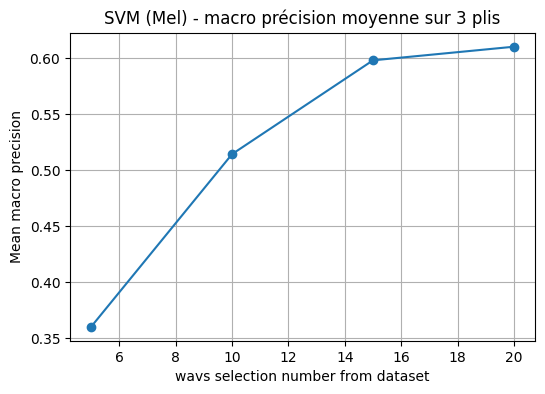

In [5]:
selections = [5, 10, 15, 20]
list_mean_macro_precision = []

for selection_nb in selections:
    list_macro_precision = []        # remise à zéro : une moyenne par taille de sélection
    for k in range(1, CROSS_NUMBER + 1):
        print(f"########## - Process KFold{k} (selection_nb={selection_nb})")

        X_train, y_train = extractMelSpectrogram_features(f"train_kfold{k}", selection_nb)
        print(f"#SVM: {X_train.shape[0]} échantillons, {X_train.shape[1]} features")
        clf = svm.SVC(kernel="rbf")
        clf.fit(X_train, y_train)

        list_y_true, list_y_pred = getPrediction(f"test_kfold{k}", clf, selection_nb)

        # target_names dans l'ordre des labels : 0 = normal, 1 = abnormal.
        cl_report = classification_report(list_y_true, list_y_pred, labels=[0, 1],
                                          target_names=TYPES, output_dict=True,
                                          zero_division=0)
        macro_precision = cl_report["macro avg"]["precision"]
        list_macro_precision.append(macro_precision)
        print(f"- Macro avg Precision: {macro_precision}")

        cm = ConfusionMatrix(actual_vector=list_y_true, predict_vector=list_y_pred)
        (DATA_DIR / f"kfold{k}_report.txt").write_text(f"{cm}\n", encoding="utf-8")

    mean_macro_precision = float(np.mean(list_macro_precision))
    list_mean_macro_precision.append(mean_macro_precision)
    print(f"##############---- wavs selection number from dataset: {selection_nb}")
    print(f"#######---- Mean macro precision: {mean_macro_precision}")

plt.figure(figsize=(6, 4))
plt.plot(selections, list_mean_macro_precision, marker="o")
plt.xlabel("wavs selection number from dataset")
plt.ylabel("Mean macro precision")
plt.title("SVM (Mel) - macro précision moyenne sur 3 plis")
plt.grid(True)
plt.show()

## 4. Amélioration du SVM

Le SVM du TP plafonne (macro précision ≈ 0,5 – 0,6) pour cinq raisons :

1. **Features pauvres** : `S_DB.flatten()[:1200]` ne garde que les 1 200 premières valeurs du
   spectrogramme (quelques bandes Mel des premières trames seulement).
2. **Échelles non normalisées** : coefficients Mel et MFCC ont des amplitudes très différentes,
   le noyau RBF est donc dominé par les grandes valeurs.
3. **Déséquilibre** : ≈ 24 % de segments `abnormal` → sans pondération, le SVM privilégie `normal`.
4. **Hyperparamètres par défaut** : `C` et `gamma` jamais réglés.
5. **Très peu de données** : 5 à 20 fichiers par classe seulement.

Version améliorée :

- **46 features par segment de 5 s** (MFCC moyenne/écart-type, ZCR, centroïde, RMS) calculées par
  `preprocess.py` — exactement le prétraitement du modèle déployé (`cardio_model.onnx`), donc
  les scores sont comparables d'un pipeline à l'autre ;
- **`StandardScaler`** puis **`SVC(rbf, class_weight="balanced")`** dans un `Pipeline` ;
- **`GridSearchCV`** sur `C` et `gamma`, avec une validation croisée **groupée par enregistrement**
  (`GroupKFold`) : tous les segments d'un même WAV restent dans le même pli, sinon les segments
  quasi identiques d'un fichier test seraient aussi dans l'entraînement (fuite de données) ;
- **réentraînement sur toutes les données** puis **sauvegarde du meilleur modèle** dans
  `audio_engine/models/best_svm.joblib` (+ métadonnées JSON).

> Le cache `models/tp3_features_segments.npz` évite de recalculer les features (~1 min 30) :
> appeler `extract_segment_features(force=True)` après une modification de `preprocess.py`.

In [6]:
import json
import sys
from collections import defaultdict
from datetime import datetime

import joblib
import sklearn
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve)

# Dossier du notebook = audio_engine/ (il contient preprocess.py)
AUDIO_ENGINE_DIR = DATA_DIR.parent.parent / "audio_engine"
sys.path.insert(0, str(AUDIO_ENGINE_DIR))
from preprocess import AudioError, Preprocessor

MODEL_DIR = AUDIO_ENGINE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
CACHE_PATH = MODEL_DIR / "tp3_features_segments.npz"

# sr=2000 Hz, passe-bande 25-400 Hz, segments de 5 s avec 50 % de recouvrement
pre = Preprocessor()
print("Dossier des modèles :", MODEL_DIR)
print(f"Features par segment : {len(pre.names)}")

Dossier des modèles : C:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models
Features par segment : 46


In [7]:
def extract_segment_features(force=False):
    """46 features par segment de 5 s, mises en cache sur disque."""
    if CACHE_PATH.exists() and not force:
        data = np.load(CACHE_PATH, allow_pickle=True)
        print(f"Cache réutilisé : {CACHE_PATH.name} ({len(data['X'])} segments)")
        return data["X"], data["files"], data["y"]

    # label explicite : attention, "normal" est contenu dans "abnormal"
    recordings = ([(f, 0) for f in sorted((DATA_DIR / "normal").glob("*.wav"))] +
                  [(f, 1) for f in sorted((DATA_DIR / "abnormal").glob("*.wav"))])

    X_list, files_list, labels_list = [], [], []
    for i, (file, label) in enumerate(recordings, start=1):
        try:
            signal = pre.load_clean(file.read_bytes())
        except AudioError as error:            # fichier trop court / silencieux / illisible
            print(f"  ignoré {file.name}: {error}")
            continue
        segments = pre.segment(signal)
        X_list.append(pre.batch(segments, "features"))
        files_list += [file.name] * len(segments)
        labels_list += [label] * len(segments)
        if i % 500 == 0:
            print(f"  {i}/{len(recordings)} fichiers, {sum(map(len, X_list))} segments")

    X_all = np.vstack(X_list).astype(np.float32)
    files_all = np.array(files_list)
    y_all = np.array(labels_list, dtype=np.int8)
    np.savez_compressed(CACHE_PATH, X=X_all, files=files_all, y=y_all,
                        feat_names=np.array(pre.names))
    print(f"Cache écrit : {CACHE_PATH}")
    return X_all, files_all, y_all


X_all, files_all, y_all = extract_segment_features()
print(f"{len(y_all)} segments, {len(np.unique(files_all))} enregistrements")
print(f"normal : {(y_all == 0).sum()} segments | abnormal : {(y_all == 1).sum()} segments")

Cache réutilisé : tp3_features_segments.npz (24990 segments)
24990 segments, 3779 enregistrements
normal : 18886 segments | abnormal : 6104 segments


### 4.1 Évaluation sur les 3 mêmes plis que la section 1

In [8]:
# Mêmes plis que la section 1. Les clés sont "classe/nom.wav" : 2 noms existent à la fois
# dans normal/ et abnormal/, un simple nom de fichier serait ambigu.
keys_all = np.array([f"{label}/{name}" for label, name in zip(y_all, files_all)])

fold_splits = []
for (normal_train_idx, normal_test_idx), (abnormal_train_idx, abnormal_test_idx) in zip(
        kf.split(normal), kf.split(abnormal)):
    fold_splits.append((
        {f"0/{Path(f).name}" for f in normal[normal_train_idx]} |
        {f"1/{Path(f).name}" for f in abnormal[abnormal_train_idx]},
        {f"0/{Path(f).name}" for f in normal[normal_test_idx]} |
        {f"1/{Path(f).name}" for f in abnormal[abnormal_test_idx]},
    ))

PARAM_GRID = {"svc__C": [1, 10, 100], "svc__gamma": [0.01, 0.03, "scale"]}


def make_svm():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", class_weight="balanced")),
    ])


fold_rows = []
fold_outputs = []                         # scores par pli : ROC et matrices de confusion
param_scores = defaultdict(list)          # hyperparamètres -> scores CV des 3 plis

for k, (train_keys, test_keys) in enumerate(fold_splits, start=1):
    train_mask = np.isin(keys_all, list(train_keys))
    test_mask = np.isin(keys_all, list(test_keys))

    search = GridSearchCV(make_svm(), PARAM_GRID, cv=GroupKFold(n_splits=CROSS_NUMBER),
                          scoring="balanced_accuracy", n_jobs=-1)
    search.fit(X_all[train_mask], y_all[train_mask], groups=files_all[train_mask])

    for params, score in zip(search.cv_results_["params"], search.cv_results_["mean_test_score"]):
        param_scores[tuple(sorted(params.items()))].append(score)

    scores = search.decision_function(X_all[test_mask])
    y_pred = (scores > 0).astype(int)
    y_test = y_all[test_mask]
    fold_outputs.append({"fold": k, "y_true": y_test, "scores": scores, "y_pred": y_pred})

    row = {
        "fold": k,
        "best_params": search.best_params_,
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "macro_precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_test, scores),
    }
    fold_rows.append(row)
    print(f"pli {k}: {search.best_params_}")
    print(f"        exactitude={row['accuracy']:.3f}  BA={row['balanced_accuracy']:.3f}  "
          f"macro précision={row['macro_precision']:.3f}  macro F1={row['macro_f1']:.3f}  "
          f"AUC={row['roc_auc']:.3f}")

metrics = ("accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "roc_auc")
improved = {m: float(np.mean([row[m] for row in fold_rows])) for m in metrics}

# Meilleurs hyperparamètres = meilleur score CV moyen sur les 3 plis
BEST_PARAMS = dict(max(param_scores, key=lambda p: np.mean(param_scores[p])))
CV_SCORE = float(np.mean(param_scores[max(param_scores, key=lambda p: np.mean(param_scores[p]))]))

baseline_mp = list_mean_macro_precision[-1] if list_mean_macro_precision else float("nan")
print("\n" + "-" * 62)
print(f"Référence TP (Mel 1200, {selections[-1]} fichiers/classe) : macro précision = {baseline_mp:.3f}")
print(f"SVM amélioré (46 features segmentées, 3 plis)          : macro précision = {improved['macro_precision']:.3f}")
print(f"                                                        exactitude      = {improved['accuracy']:.3f}")
print(f"                                                        BA              = {improved['balanced_accuracy']:.3f}")
print(f"                                                        macro F1        = {improved['macro_f1']:.3f}")
print(f"                                                        AUC             = {improved['roc_auc']:.3f}")
print(f"Meilleurs hyperparamètres : {BEST_PARAMS} (BA CV = {CV_SCORE:.3f})")

pli 1: {'svc__C': 1, 'svc__gamma': 0.01}
        exactitude=0.863  BA=0.887  macro précision=0.813  macro F1=0.835  AUC=0.940
pli 2: {'svc__C': 1, 'svc__gamma': 0.01}
        exactitude=0.857  BA=0.880  macro précision=0.809  macro F1=0.830  AUC=0.933
pli 3: {'svc__C': 1, 'svc__gamma': 0.01}
        exactitude=0.857  BA=0.880  macro précision=0.809  macro F1=0.829  AUC=0.935

--------------------------------------------------------------
Référence TP (Mel 1200, 20 fichiers/classe) : macro précision = 0.610
SVM amélioré (46 features segmentées, 3 plis)          : macro précision = 0.810
                                                        exactitude      = 0.859
                                                        BA              = 0.883
                                                        macro F1        = 0.831
                                                        AUC             = 0.936
Meilleurs hyperparamètres : {'svc__C': 1, 'svc__gamma': 0.01} (BA CV = 0.872)


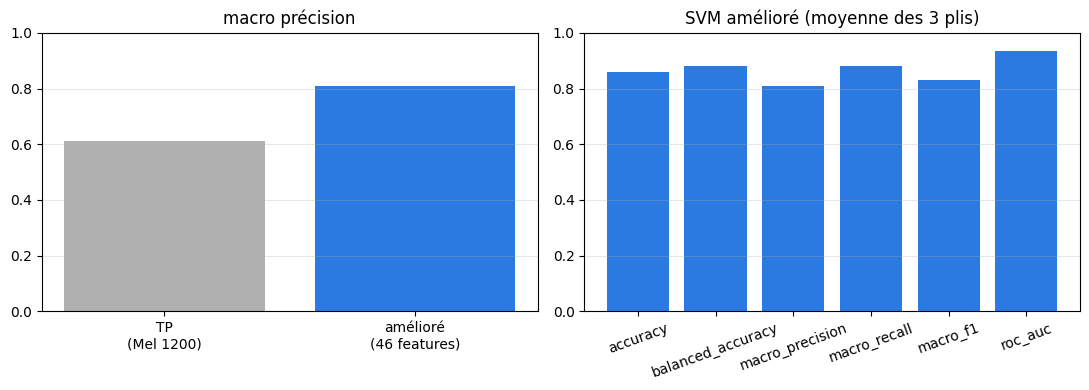

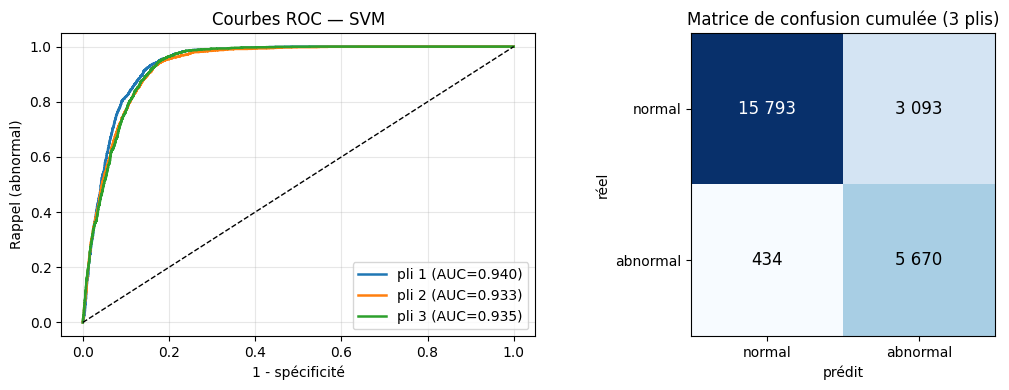

In [9]:
PLOT_DIR = MODEL_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# --- Figure 1 : référence TP vs SVM amélioré
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(["TP\n(Mel 1200)", "amélioré\n(46 features)"],
            [baseline_mp, improved["macro_precision"]], color=["#b0b0b0", "#2a7ae2"])
axes[0].set_ylim(0, 1)
axes[0].set_title("macro précision")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(metrics, [improved[m] for m in metrics], color="#2a7ae2")
axes[1].set_ylim(0, 1)
axes[1].set_title("SVM amélioré (moyenne des 3 plis)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
COMPARISON_PLOT = PLOT_DIR / "tp3_svm_comparison.png"
fig.savefig(COMPARISON_PLOT, dpi=150)
plt.show()

# --- Figure 2 : ROC et matrice de confusion cumulée sur les 3 plis
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for out in fold_outputs:
    fpr, tpr, _ = roc_curve(out["y_true"], out["scores"])
    axes[0].plot(fpr, tpr, lw=1.8, label=f"pli {out['fold']} (AUC={roc_auc_score(out['y_true'], out['scores']):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("1 - spécificité")
axes[0].set_ylabel("Rappel (abnormal)")
axes[0].set_title("Courbes ROC — SVM")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

cm_total = sum(confusion_matrix(out["y_true"], out["y_pred"], labels=[0, 1]) for out in fold_outputs)
axes[1].imshow(cm_total, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm_total[i, j]:,}".replace(",", " "), ha="center", va="center",
                     color="white" if cm_total[i, j] > cm_total.max() / 2 else "black", fontsize=12)
axes[1].set_xticks([0, 1], ["normal", "abnormal"])
axes[1].set_yticks([0, 1], ["normal", "abnormal"])
axes[1].set_xlabel("prédit")
axes[1].set_ylabel("réel")
axes[1].set_title("Matrice de confusion cumulée (3 plis)")

fig.tight_layout()
ROC_PLOT = PLOT_DIR / "tp3_svm_roc_confusion.png"
fig.savefig(ROC_PLOT, dpi=150)
plt.show()

### 4.3 Courbes d'apprentissage par pli

Pour chaque pli, on trace le score (balanced accuracy) et la perte (`1 - score`) en
fonction du nombre de segments d'entra?nement. La validation interne est un
`GroupKFold(3)` group? par enregistrement : aucun WAV ne fuit entre train et validation.
Les courbes sont aussi envoy?es ? MLflow (`foldK_lc_*`) avec les figures et les CSV.


In [10]:
# --- Courbes d'apprentissage par pli (train vs validation CV group?e) ---
from fold_utils import (compute_learning_curve, plot_all_folds_learning_curves,
                        plot_learning_curve, save_learning_curve_csv)

learning_curves, lc_histories, lc_artifacts = [], [], {}

for k, (train_keys, test_keys) in enumerate(fold_splits, start=1):
    train_mask = np.isin(keys_all, list(train_keys))
    estimator = make_svm().set_params(**BEST_PARAMS)
    curve = compute_learning_curve(
        estimator, X_all[train_mask], y_all[train_mask], groups=files_all[train_mask],
        train_sizes=np.linspace(0.1, 1.0, 5), cv_splits=CROSS_NUMBER,
        scoring="balanced_accuracy", n_jobs=-1, random_state=SEED,
    )
    curve["fold"] = k
    learning_curves.append(curve)

    plot_path = plot_learning_curve(curve, k, PLOT_DIR, "svm")
    csv_path = save_learning_curve_csv(curve, MODEL_DIR / f"svm_fold{k}_learning_curve.csv")
    lc_artifacts[str(plot_path)] = "plots"
    lc_artifacts[str(csv_path)] = "curves"
    lc_histories.append({
        "fold": k,
        "steps": curve["train_sizes"],
        "metrics": {
            "lc_train_score": curve["train_score_mean"],
            "lc_val_score": curve["val_score_mean"],
            "lc_train_loss": curve["train_loss_mean"],
            "lc_val_loss": curve["val_loss_mean"],
        },
    })
    print(f"pli {k} : {curve['train_sizes']} segments | "
          f"score validation final = {curve['val_score_mean'][-1]:.3f}")

LC_ALL_PLOT = plot_all_folds_learning_curves(learning_curves, PLOT_DIR, "svm")
lc_artifacts[str(LC_ALL_PLOT)] = "plots"
print("Courbes d'apprentissage :", LC_ALL_PLOT)


pli 1 : [1122, 3647, 6173, 8698, 11224] segments | score validation final = 0.871
pli 2 : [1121, 3643, 6165, 8687, 11210] segments | score validation final = 0.872
pli 3 : [1088, 3537, 5987, 8436, 10886] segments | score validation final = 0.872
Courbes d'apprentissage : C:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\plots\svm_learning_curves_all_folds.png


### 4.2 Réentraînement final et sauvegarde du meilleur SVM dans `audio_engine/`

In [11]:
# --- Réentraînement sur TOUTES les données (normal + abnormal) avec les meilleurs hyperparamètres
best_svm = make_svm().set_params(**BEST_PARAMS)
best_svm.fit(X_all, y_all)

MODEL_PATH = MODEL_DIR / "best_svm.joblib"
META_PATH = MODEL_DIR / "best_svm_meta.json"
joblib.dump(best_svm, MODEL_PATH, compress=3)

meta = {
    "model": "Pipeline(StandardScaler, SVC(kernel='rbf', class_weight='balanced'))",
    "file": str(MODEL_PATH),
    "created_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "best_params": BEST_PARAMS,
    "cv": f"GridSearchCV + GroupKFold({CROSS_NUMBER}) groupé par enregistrement",
    "cv_balanced_accuracy": CV_SCORE,
    "fold_metrics": fold_rows,
    "mean_metrics": improved,
    "baseline_tp_macro_precision": float(baseline_mp),
    "features": {
        "source": "preprocess.Preprocessor",
        "n_features": len(pre.names),
        "names": list(pre.names),
        "sample_rate": pre.sr,
        "segment_sec": pre.seg_len / pre.sr,
        "hop_sec": pre.hop_len / pre.sr,
    },
    "labels": {"0": "normal", "1": "abnormal"},
    "n_segments": int(len(y_all)),
    "n_recordings": int(len(np.unique(files_all))),
    "class_counts": {"normal": int((y_all == 0).sum()), "abnormal": int((y_all == 1).sum())},
    "versions": {"sklearn": sklearn.__version__, "librosa": librosa.__version__},
    "usage": "clf = joblib.load('models/best_svm.joblib'); "
             "sig = pre.load_clean(open(wav, 'rb').read()); "
             "X = pre.batch(pre.segment(sig), 'features'); clf.predict(X)",
}
META_PATH.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Modèle entraîné sur {len(y_all)} segments ({len(np.unique(files_all))} enregistrements)")
print(f"Modèle sauvegardé : {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} Mo)")
print(f"Métadonnées       : {META_PATH}")
print(f"Hyperparamètres   : {BEST_PARAMS}")

Modèle entraîné sur 24990 segments (3779 enregistrements)
Modèle sauvegardé : C:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\best_svm.joblib (1.5 Mo)
Métadonnées       : C:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\best_svm_meta.json
Hyperparamètres   : {'svc__C': 1, 'svc__gamma': 0.01}


In [12]:
# --- Vérification : le modèle rechargé depuis le disque prédit correctement un enregistrement
def predict_recording(path, clf=None):
    """Prédit une classe au niveau de l'enregistrement (moyenne des scores des segments)."""
    clf = best_svm if clf is None else clf
    signal = pre.load_clean(Path(path).read_bytes())
    features = pre.batch(pre.segment(signal), "features")
    score = float(clf.decision_function(features).mean())
    return ("abnormal" if score > 0 else "normal"), score


loaded = joblib.load(MODEL_PATH)
print("Modèle rechargé :", loaded)
for nametype in ("normal", "abnormal"):
    demo_file = sorted((DATA_DIR / nametype).glob("*.wav"))[0]
    predicted, score = predict_recording(demo_file, loaded)
    print(f"  {demo_file.name:>28} : attendu={nametype:<8} prédit={predicted:<8} score={score:+.2f}")

Modèle rechargé : Pipeline(steps=[('scaler', StandardScaler()),
                ('svc', SVC(C=1, class_weight='balanced', gamma=0.01))])
       101_1305030823364_B.wav : attendu=normal   prédit=normal   score=-0.34
       112_1306243000964_A.wav : attendu=abnormal prédit=abnormal score=+0.23


## 5. Suivi MLflow

Les trois modèles du TP (SVM, arbre de décision et CNN — notebook `CNN.ipynb`)
sont enregistrés dans la **même expérience** `tp3_audio_engine` du serveur MLflow
(`http://localhost:5000`) : ils sont donc comparables directement dans l'interface.

Le run contient : hyperparamètres, métriques par pli et moyennes, figures (comparaison,
ROC, matrice de confusion), le fichier `best_svm.joblib`, ses métadonnées JSON et le
modèle sérialisé par `mlflow.sklearn`. Si le serveur est arrêté, `mlflow_utils.py` bascule
automatiquement sur `audio_engine/mlruns.db`.

In [13]:
import sys
sys.path.insert(0, str(AUDIO_ENGINE_DIR))
from mlflow_utils import log_classifier_run

mlflow_params = {
    "model": "SVM",
    "kernel": "rbf",
    "C": BEST_PARAMS["svc__C"],
    "gamma": BEST_PARAMS["svc__gamma"],
    "class_weight": "balanced",
    "scaler": "StandardScaler",
    "cv": f"GridSearchCV + GroupKFold({CROSS_NUMBER}) groupé par enregistrement",
    "protocol": "3 folds au niveau enregistrement (KFold(3, shuffle=True, random_state=10))",
    "n_features": len(pre.names),
    "n_segments": len(y_all),
    "n_recordings": int(len(np.unique(files_all))),
    "pos_rate": float((y_all == 1).mean()),
    "sample_rate": pre.sr,
    "segment_seconds": pre.seg_len / pre.sr,
    "hop_seconds": pre.hop_len / pre.sr,
    "bandpass": "25-400 Hz",
    "n_fft": pre.n_fft,
    "hop_length": pre.hop,
    "n_mels": pre.n_mels,
    "n_mfcc": pre.n_mfcc,
    "baseline_tp_macro_precision": float(baseline_mp),
}

tracking_uri, run_id = log_classifier_run(
    run_name="svm_rbf_segments",
    model=best_svm,
    params=mlflow_params,
    mean_metrics={**improved, "cv_balanced_accuracy": CV_SCORE},
    fold_metrics=fold_rows,
    histories=lc_histories,
    artifacts={MODEL_PATH: "models", META_PATH: "models",
               COMPARISON_PLOT: "plots", ROC_PLOT: "plots", **lc_artifacts},
    input_example=X_all[:5],
)

2026/11/21 12:55:05 INFO mlflow.tracking._tracking_service.client: 🏃 View run svm_rbf_segments at: http://localhost:5000/#/experiments/9/runs/77d579fe07d2415fb5800ba469a590f1.
2026/11/21 12:55:05 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5000/#/experiments/9.


[MLflow] run 'svm_rbf_segments' enregistré : http://localhost:5000 / tp3_audio_engine (id=9)
[MLflow] http://localhost:5000/#/experiments/9/runs/77d579fe07d2415fb5800ba469a590f1
[MLflow] run_id = 77d579fe07d2415fb5800ba469a590f1
